# 02 — Double descent with two-layer neural networks on MNIST

Reproduces **Figure 4** (and Figure 9a/9c) of Belkin et al. (2019).

**What this notebook does**

1. Takes `n` MNIST training images (paper: n = 4,000).
2. Trains fully connected networks with one hidden layer, 784 → H → 10 (ReLU), for many widths H.
3. Training follows the paper (Appendix C.3): **squared loss** on one-hot labels, **SGD with momentum 0.95**, up to 6,000 epochs.
4. Records train/test zero-one error and squared loss for each H, for several seeds.

**Number of parameters** of a network with H hidden units: $P = (d+1)H + (H+1)K$ with d = 784, K = 10.
To fit n points exactly with K outputs we need n·K equations satisfied, so the **interpolation threshold** is expected near $P \approx nK$ = 40,000, i.e. H ≈ 50.

**Two modes** (set `WEIGHT_REUSE` in the settings):

- `True` (paper Fig. 4 / 9a): below the threshold, each network starts from the trained weights of the previous, smaller network. This makes training error decrease steadily with H. Above the threshold, networks start from a fresh random initialisation.
- `False` (paper Fig. 9c): every network starts from a fresh random initialisation. The paper says the peak is still visible, but with more variance.

**Expected result:** test error peaks near P = nK and decreases again for larger networks.

## 1. Settings
Start with `PILOT = True` (a few minutes) to check everything works. Then set `PILOT = False` for the real run.

In [1]:
PILOT = False          # True: small, fast check. False: the real experiment.
WEIGHT_REUSE = True    # True: paper Fig. 4 / 9(a).  False: paper Fig. 9(c).

if PILOT:
    N_TRAIN = 1_000
    SEEDS = [0]
    MAX_EPOCHS = 6_000
else:
    N_TRAIN = 4_000    # paper: n = 4 * 10^3
    SEEDS = [0, 1, 2]  # course requires >= 3 seeds
    MAX_EPOCHS = 6_000 # paper: 6,000 epochs

# Network sizes, as multiples of the threshold n*K parameters. Dense around 1.0.
P_FRACTIONS = [0.1, 0.2, 0.4, 0.6, 0.8, 0.9, 1.0, 1.1, 1.2, 1.5, 2, 4, 8, 20]

LR = 0.001             # NOT stated in the paper. With our summed squared loss this equals Keras MSE (mean over 10 outputs) at its default LR 0.01. Chosen on training error and dead units.
WARMUP_STEPS = 1_600   # NOT in the paper: linear LR warmup; without it fresh-init nets lost ~50% of hidden units in the first ~80 steps
MOMENTUM = 0.95        # paper Appendix C.3
BATCH_SIZE = 128       # NOT stated in the paper
LR_DECAY = 0.9         # paper: "decay the step size by 10% after each of 500 epochs" (below threshold only)
DECAY_EVERY = 500
EVAL_EVERY = 10        # check train error every 10 epochs (for early stopping below the threshold)

D_IN, K = 784, 10
DRIVE_DIR = "/content/drive/MyDrive/double-descent"
TAG = (f"pilot_ep{MAX_EPOCHS}_lr{LR}_wu{WARMUP_STEPS}" if PILOT else "full") + ("_reuse" if WEIGHT_REUSE else "_noreuse")
RESULTS_CSV = f"{DRIVE_DIR}/results/mlp_mnist_{TAG}.csv"
CKPT_DIR = f"{DRIVE_DIR}/checkpoints/mlp_mnist_{TAG}"

## 2. Setup: Drive, imports, device

In [2]:
import os, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

for sub in ["results", "checkpoints", "figures"]:
    os.makedirs(f"{DRIVE_DIR}/{sub}", exist_ok=True)
os.makedirs(CKPT_DIR, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float32   # float32 is fine here: SGD is not sensitive to rounding the way the RFF solver is
print("device:", DEVICE, "| torch", torch.__version__)

Mounted at /content/drive
device: cuda | torch 2.14.1+cu130


## 3. Shared helpers (identical in every notebook)

In [3]:
import torchvision

def load_mnist_subset(n_train, seed, root="/content/data"):
    train = torchvision.datasets.MNIST(root, train=True, download=True)
    test = torchvision.datasets.MNIST(root, train=False, download=True)
    g = torch.Generator().manual_seed(seed)
    idx = torch.randperm(len(train.targets), generator=g)[:n_train]
    def prep(images, labels):
        X = images.reshape(len(images), -1).to(DTYPE) / 255.0          # (m, 784), values in [0, 1]
        Y = torch.nn.functional.one_hot(labels, 10).to(DTYPE)          # (m, 10)
        return X.to(DEVICE), Y.to(DEVICE)
    Xtr, Ytr = prep(train.data[idx], train.targets[idx])
    Xte, Yte = prep(test.data, test.targets)
    return Xtr, Ytr, Xte, Yte

def append_result(path, row):
    pd.DataFrame([row]).to_csv(path, mode="a", header=not os.path.exists(path), index=False)

def done_keys(path, cols):
    if not os.path.exists(path):
        return set()
    return set(map(tuple, pd.read_csv(path)[cols].values.tolist()))

def zero_one(P, Y):   # % of points where the predicted class (largest output) is wrong
    return 100.0 * (P.argmax(1) != Y.argmax(1)).double().mean().item()

def sq_loss(P, Y):    # squared loss summed over the 10 outputs, averaged over points
    return ((P - Y) ** 2).sum(1).mean().item()

## 4. Model, initialisation and weight reuse

**Model.** $f(x) = W_2\,\mathrm{ReLU}(W_1 x + b_1) + b_2$ with $W_1 \in \mathbb R^{H\times 784}$, $W_2 \in \mathbb R^{10\times H}$.

**Initialisation** (paper Appendix C.3):

- A network that does not reuse weights: Glorot (Xavier) uniform for $W_1, W_2$, zero biases (lecture 6: Xavier keeps the variance of activations constant across layers).
- **Weight reuse**: a larger network with $H_2 > H_1$ hidden units copies the $H_1$ trained units of the smaller network (rows of $W_1$, entries of $b_1$, columns of $W_2$, and $b_2$). The extra weights are drawn from $\mathcal N(0, 0.01)$: variance 0.01, i.e. standard deviation 0.1. At the start, the larger network therefore computes almost the same function as the trained smaller one, so its training error can only go down.

**Loss.** Squared loss on one-hot targets, $\frac1B\sum_{i}\|f(x_i) - y_i\|^2$, exactly as in the paper. (Cross-entropy would be the usual choice for classification, but the paper's claim is about the squared loss.)

**Learning rate.** The paper does not give the step size or the batch size. We use batch 128 and pick the largest learning rate for which training loss decreases smoothly in the pilot run. This uses training data only, never the test set.

In [4]:
def n_params(H):
    return (D_IN + 1) * H + (H + 1) * K

def make_model(H):
    model = nn.Sequential(nn.Linear(D_IN, H), nn.ReLU(), nn.Linear(H, K))
    for layer in (model[0], model[2]):
        nn.init.xavier_uniform_(layer.weight)
        nn.init.zeros_(layer.bias)
    return model.to(DEVICE)

@torch.no_grad()
def grow_from(small, H_new):
    # Weight reuse: copy the trained units of `small` into a wider network; new weights ~ N(0, 0.01).
    big = make_model(H_new)
    for p in big.parameters():
        nn.init.normal_(p, mean=0.0, std=0.1)
    H_old = small[0].out_features
    big[0].weight[:H_old] = small[0].weight
    big[0].bias[:H_old] = small[0].bias
    big[2].weight[:, :H_old] = small[2].weight
    big[2].bias[:] = small[2].bias
    return big

H_THRESHOLD = (N_TRAIN * K - K) / (D_IN + 1 + K)       # H where P = n*K
H_LIST = sorted({max(1, round((f * N_TRAIN * K - K) / (D_IN + 1 + K))) for f in P_FRACTIONS})
print(f"threshold: P = n*K = {N_TRAIN * K}  ->  H ≈ {H_THRESHOLD:.1f}")
print("H values:", H_LIST)
print("P values:", [n_params(H) for H in H_LIST])

threshold: P = n*K = 40000  ->  H ≈ 50.3
H values: [5, 10, 20, 30, 40, 45, 50, 55, 60, 75, 101, 201, 403, 1006]
P values: [3985, 7960, 15910, 23860, 31810, 35785, 39760, 43735, 47710, 59635, 80305, 159805, 320395, 799780]


## 5. Training loop

The whole training set sits on the GPU and we cut it into random mini-batches ourselves (a `DataLoader` would be about 10× slower for such a small model).

- **Below the threshold** ($P < nK$): the learning rate is multiplied by 0.9 every 500 epochs, and training stops early once training error reaches 0% (paper).
- **At or above the threshold**: fixed learning rate, always `MAX_EPOCHS` epochs (paper).

In [5]:
def train(model, Xtr, Ytr, below_threshold, seed):
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    opt = torch.optim.SGD(model.parameters(), lr=LR, momentum=MOMENTUM)
    n = len(Xtr)
    base_lr = LR          # LR after warmup; decayed below the threshold
    step = 0
    epoch = 0
    for epoch in range(1, MAX_EPOCHS + 1):
        perm = torch.randperm(n, device=DEVICE, generator=g)
        for i in range(0, n, BATCH_SIZE):
            step += 1
            lr_now = base_lr * min(1.0, step / WARMUP_STEPS)   # linear warmup over the first WARMUP_STEPS steps
            for group in opt.param_groups:
                group["lr"] = lr_now
            idx = perm[i:i + BATCH_SIZE]
            loss = ((model(Xtr[idx]) - Ytr[idx]) ** 2).sum(1).mean()
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
        if not torch.isfinite(loss):
            raise RuntimeError(f"loss became {loss.item()} at epoch {epoch}: learning rate too large")
        if below_threshold and epoch % DECAY_EVERY == 0:
            base_lr *= LR_DECAY
        if below_threshold and epoch % EVAL_EVERY == 0:
            with torch.no_grad():
                if zero_one(model(Xtr), Ytr) == 0.0:
                    break
    return epoch

@torch.no_grad()
def evaluate(model, Xtr, Ytr, Xte, Yte):
    Ptr, Pte = model(Xtr), model(Xte)
    return dict(train_err=zero_one(Ptr, Ytr), test_err=zero_one(Pte, Yte),
                train_mse=sq_loss(Ptr, Ytr), test_mse=sq_loss(Pte, Yte))

@torch.no_grad()
def dead_units(model, X):
    # hidden units whose ReLU output is 0 for every training image
    act = torch.relu(model[0](X))
    return int((act.max(0).values == 0).sum().item())

## 6. Run the experiment

Networks are trained from small to large. After each network: one row is appended to the CSV and the weights are saved to `checkpoints/`. If the session disconnects, re-run all cells: finished networks are skipped, and weight reuse continues from the last saved network.

To use several Colab accounts at once, give each account a different seed (e.g. `SEEDS = [1]` on the second account). All of them write to the same CSV in the shared Drive folder.

In [6]:
done = done_keys(RESULTS_CSV, ["seed", "H"])
print(f"n = {N_TRAIN}, seeds = {SEEDS}, weight reuse = {WEIGHT_REUSE}, max epochs = {MAX_EPOCHS}")

for seed in SEEDS:
    Xtr, Ytr, Xte, Yte = load_mnist_subset(N_TRAIN, seed)
    prev = None                                   # previous (smaller) trained network, for weight reuse
    for H in H_LIST:
        ckpt = f"{CKPT_DIR}/seed{seed}_H{H}.pt"
        below = n_params(H) < N_TRAIN * K
        if (seed, H) in done:                     # already trained: reload it so the reuse chain continues
            prev = make_model(H)
            prev.load_state_dict(torch.load(ckpt, map_location=DEVICE))
            continue
        torch.manual_seed(10_000 * seed + H)      # makes the random initialisation reproducible
        if WEIGHT_REUSE and below and prev is not None:
            model = grow_from(prev, H)
        else:
            model = make_model(H)
        t0 = time.time()
        epochs = train(model, Xtr, Ytr, below, seed)
        r = evaluate(model, Xtr, Ytr, Xte, Yte)
        r["dead"] = dead_units(model, Xtr)
        torch.save(model.state_dict(), ckpt)
        row = dict(seed=seed, n=N_TRAIN, H=H, P=n_params(H), reuse=WEIGHT_REUSE, epochs=epochs,
                   **r, seconds=round(time.time() - t0, 1))
        append_result(RESULTS_CSV, row)
        print(f"seed {seed}  H={H:5d}  P={n_params(H):8d}  epochs {epochs:5d}  "
              f"train {r['train_err']:5.1f}% / {r['train_mse']:.4f}  test {r['test_err']:5.1f}% / {r['test_mse']:.3f}  "
              f"({row['seconds']} s)")
        prev = model

n = 4000, seeds = [0, 1, 2], weight reuse = True, max epochs = 6000


100%|██████████| 9.91M/9.91M [00:01<00:00, 4.99MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 131kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.25MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.97MB/s]


## 7. Results table (mean ± std over seeds)

In [7]:
df = pd.read_csv(RESULTS_CSV)
summary = df.groupby(["H", "P"])[["epochs", "dead", "train_err", "test_err", "train_mse", "test_mse"]].agg(["mean", "std"]).round(3)
display(summary)

epochs        dead        train_err        test_err         \
               mean  std   mean    std      mean    std     mean    std   
H    P                                                                    
5    3985    6000.0  0.0  0.333  0.577    41.892  5.745   48.173  3.978   
10   7960    6000.0  0.0  0.333  0.577     2.683  0.430   19.210  1.631   
20   15910   6000.0  0.0  0.333  0.577     1.692  0.298   18.110  1.107   
30   23860   6000.0  0.0  0.333  0.577     1.117  0.281   19.997  0.463   
40   31810   6000.0  0.0  0.333  0.577     1.008  0.201   21.360  0.529   
45   35785   6000.0  0.0  1.000  1.000     0.908  0.232   22.490  0.805   
50   39760   6000.0  0.0  1.000  1.000     0.833  0.275   23.890  0.805   
55   43735   6000.0  0.0  0.667  0.577     0.267  0.052   12.227  1.044   
60   47710   6000.0  0.0  0.000  0.000     0.233  0.076   11.273  0.398   
75   59635   6000.0  0.0  0.000  0.000     0.092  0.095   10.057  0.235   
101  80305   6000.0  0.0  0.000  0.000     0.042  0.014    9.130  0.499   
201  159805  6000.0  0.0  0.000  0.000     0.000  0.000    6.523  0.201   
403  320395  6000.0  0.0  0.000  0.000     0.000  0.000    5.620  0.090   
1006 799780  6000.0  0.0  0.000  0.000     0.000  0.000    4.883  0.057   

            train_mse        test_mse         
                 mean    std     mean    std  
H    P                                        
5    3985       0.449  0.048    0.597  0.010  
10   7960       0.078  0.016    0.435  0.028  
20   15910      0.047  0.003    0.457  0.031  
30   23860      0.032  0.002    0.530  0.034  
40   31810      0.025  0.004    0.613  0.040  
45   35785      0.020  0.004    0.694  0.049  
50   39760      0.017  0.004    0.765  0.057  
55   43735      0.006  0.001    0.300  0.021  
60   47710      0.007  0.001    0.275  0.016  
75   59635      0.005  0.001    0.259  0.006  
101  80305      0.004  0.000    0.243  0.013  
201  159805     0.002  0.000    0.231  0.002  
403  320395     0.000  0.000    0.233  0.005  
1006 799780     0.000  0.000    0.206  0.001

## 8. Figure 4 reproduction
Same layout as the paper: zero-one loss (top) and squared loss (bottom) against the number of parameters, log-scaled x-axis. Shaded band = ± 1 std over seeds; dotted line = interpolation threshold P = nK.

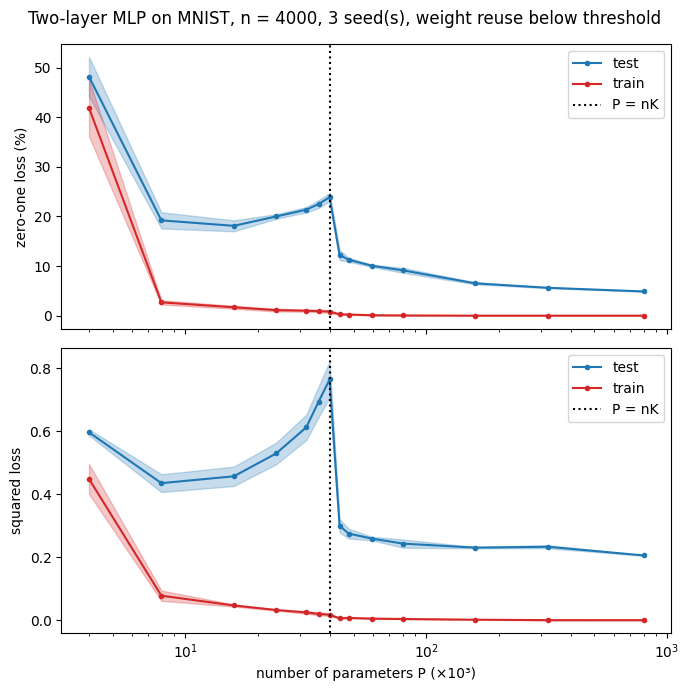

In [8]:
g = df.groupby("P")
x = np.array(sorted(df.P.unique())) / 1000
fig, axes = plt.subplots(2, 1, figsize=(7, 7), sharex=True)
for ax, (test_col, train_col, ylab) in zip(axes, [("test_err", "train_err", "zero-one loss (%)"),
                                                  ("test_mse", "train_mse", "squared loss")]):
    for col, color, label in [(test_col, "C0", "test"), (train_col, "C3", "train")]:
        m, s = g[col].mean(), g[col].std().fillna(0)
        ax.plot(x, m, "o-", ms=3, color=color, label=label)
        ax.fill_between(x, m - s, m + s, color=color, alpha=0.25)
    ax.axvline(N_TRAIN * K / 1000, color="k", ls=":", label="P = nK")
    ax.set_ylabel(ylab); ax.legend()
axes[1].set_xscale("log")
axes[1].set_xlabel("number of parameters P (×10³)")
mode = "weight reuse below threshold" if WEIGHT_REUSE else "no weight reuse"
fig.suptitle(f"Two-layer MLP on MNIST, n = {N_TRAIN}, {df.seed.nunique()} seed(s), {mode}")
fig.tight_layout()
for ext in ["pdf", "png"]:
    fig.savefig(f"{DRIVE_DIR}/figures/mlp_mnist_{TAG}.{ext}", dpi=150)
plt.show()